<h2 style="color:blue" align="center">Handwritten digits classification using neural network</h2>

In this notebook we will classify handwritten digits using a simple neural network which has only input and output layers. We will than add a hidden layer and see how the performance of the model improves

In [ ]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np

In [ ]:
from PIL import Image
import os

# Load your custom images
def load_custom_images(folder_path):
    images = []
    labels = []
    
    for filename in os.listdir(folder_path):
        if filename.lower().endswith((".png", ".jpg", ".jpeg")):
            # filename format expected: digit_5_2.png
            try:
                label = int(filename.split('_')[1])
            except (IndexError, ValueError):
                print(f"Skipping invalid filename format: {filename}")
                continue
        
            img = Image.open(os.path.join(folder_path, filename)).convert('L')
            img = img.resize((28, 28), Image.LANCZOS) # resize image to 28x28
            img_array = np.array(img, dtype=np.float32) / 255.0 # normalize pixel values to 0-1
        
            images.append(img_array)
            labels.append(label)
            
    return np.array(images), np.array(labels)

# Example usage:
x_custom, y_custom = load_custom_images('./digits')

In [ ]:
(X_train, y_train) , (X_test, y_test) = keras.datasets.mnist.load_data()

In [ ]:
len(X_train)

60000

In [ ]:
len(X_test)

10000

In [ ]:
X_train[0].shape

(28, 28)

In [ ]:
X_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

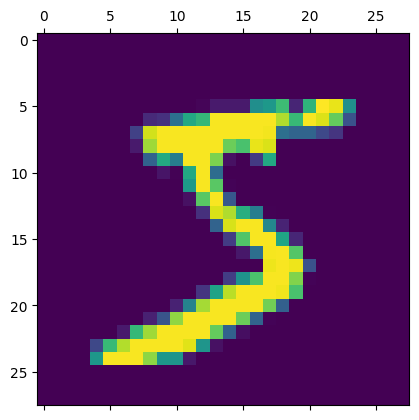

In [ ]:
plt.matshow(X_train[0])

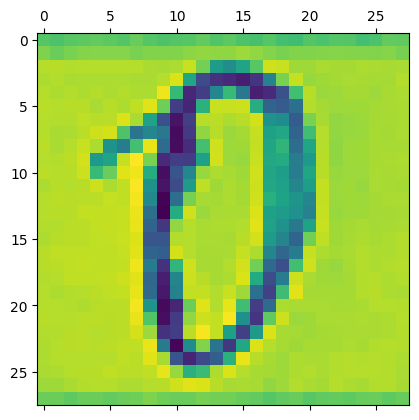

In [ ]:
plt.matshow(x_custom[0])

In [ ]:
y_train[0]

np.uint8(5)

In [ ]:
X_train = X_train / 255
X_test = X_test / 255

In [ ]:
X_train[0]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

In [ ]:
X_train_flattened = X_train.reshape(len(X_train), 28*28)
X_test_flattened = X_test.reshape(len(X_test), 28*28)
X_custom_flattened = x_custom.reshape(len(x_custom), 28*28) # flatten custom dataset

In [ ]:
X_train_flattened.shape

(60000, 784)

In [ ]:
X_custom_flattened.shape

(30, 784)

In [ ]:
X_train_flattened[0]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

<h3 style='color:purple'>Very simple neural network with no hidden layers</h3>

<img src="digits_nn.jpg" />

In [ ]:
model = keras.Sequential([
    keras.layers.Dense(10, input_shape=(784,), activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.fit(X_train_flattened, y_train, epochs=5)

d:\Users\leong\Downloads\Lecture Notes\Year 3\Semester 2\ELET3405 - Practical Analysis of Advanced Electronics Circuits ad Systems\.venv\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.8765 - loss: 0.4709
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9154 - loss: 0.3045
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9211 - loss: 0.2834
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9233 - loss: 0.2731
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9254 - loss: 0.2666


In [ ]:
model.evaluate(X_test_flattened, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9234 - loss: 0.2706


[0.27057310938835144, 0.9233999848365784]

In [ ]:
y_predicted = model.predict(X_test_flattened)
print(y_predicted[0])
print(np.argmax(y_predicted[0]))

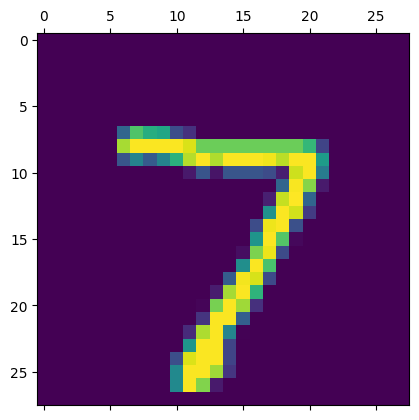

In [ ]:
plt.matshow(X_test[0])

**np.argmax finds a maximum element  from an array and returns the index of it**

In [ ]:
np.argmax(y_predicted[0])

np.int64(7)

In [ ]:
y_predicted_labels = [np.argmax(i) for i in y_predicted]

In [ ]:
y_predicted_labels[:5]

[np.int64(7), np.int64(2), np.int64(1), np.int64(0), np.int64(4)]

In [ ]:
cm = tf.math.confusion_matrix(labels=y_test,predictions=y_predicted_labels)
cm

<tf.Tensor: shape=(10, 10), dtype=int32, numpy=
array([[ 962,    0,    1,    1,    0,    5,    7,    3,    1,    0],
       [   0, 1117,    2,    2,    0,    1,    4,    2,    7,    0],
       [   8,    9,  922,   16,    8,    5,   12,   11,   37,    4],
       [   4,    0,   17,  918,    1,   23,    2,   11,   26,    8],
       [   1,    1,    5,    2,  921,    0,   10,    4,    7,   31],
       [   8,    2,    3,   22,   10,  786,   14,    5,   35,    7],
       [  10,    3,    5,    1,    8,   15,  912,    2,    2,    0],
       [   1,    6,   21,    8,    8,    1,    0,  957,    1,   25],
       [   8,    9,    7,   21,    9,   26,    8,   13,  867,    6],
       [  11,    7,    1,    8,   33,    9,    0,   30,    7,  903]],
      dtype=int32)>

Text(95.72222222222221, 0.5, 'Truth')

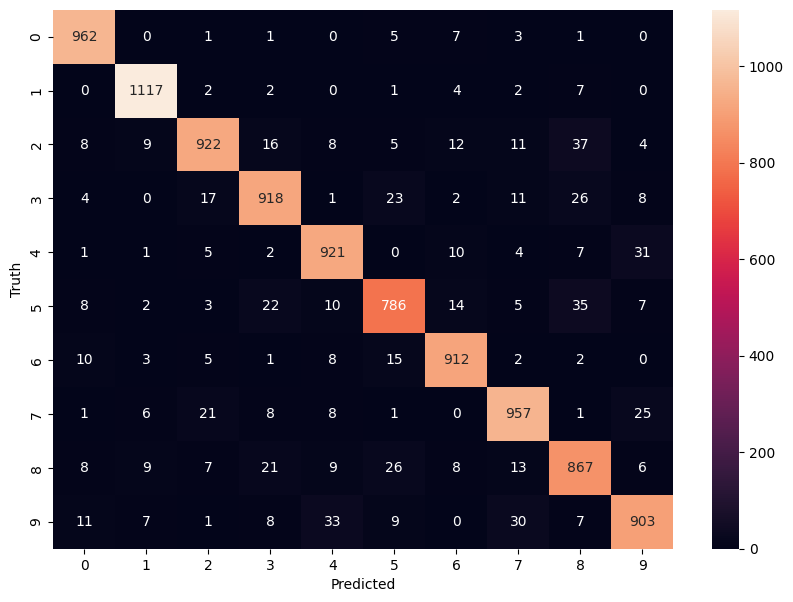

In [ ]:
import seaborn as sn
plt.figure(figsize = (10,7))
sn.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Truth')

<h3 style='color:purple'>Using hidden layer</h3>

In [ ]:
model = keras.Sequential([
    keras.layers.Dense(100, input_shape=(784,), activation='relu'),
    keras.layers.Dense(10, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.fit(X_train_flattened, y_train, epochs=5)

Epoch 1/5


d:\Users\leong\Downloads\Lecture Notes\Year 3\Semester 2\ELET3405 - Practical Analysis of Advanced Electronics Circuits ad Systems\.venv\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9211 - loss: 0.2751
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9620 - loss: 0.1280
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9728 - loss: 0.0897
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9793 - loss: 0.0670
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9837 - loss: 0.0531


In [ ]:
model.evaluate(X_test_flattened,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9734 - loss: 0.0824


[0.08238467574119568, 0.9733999967575073]

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 922us/step


Text(95.72222222222221, 0.5, 'Truth')

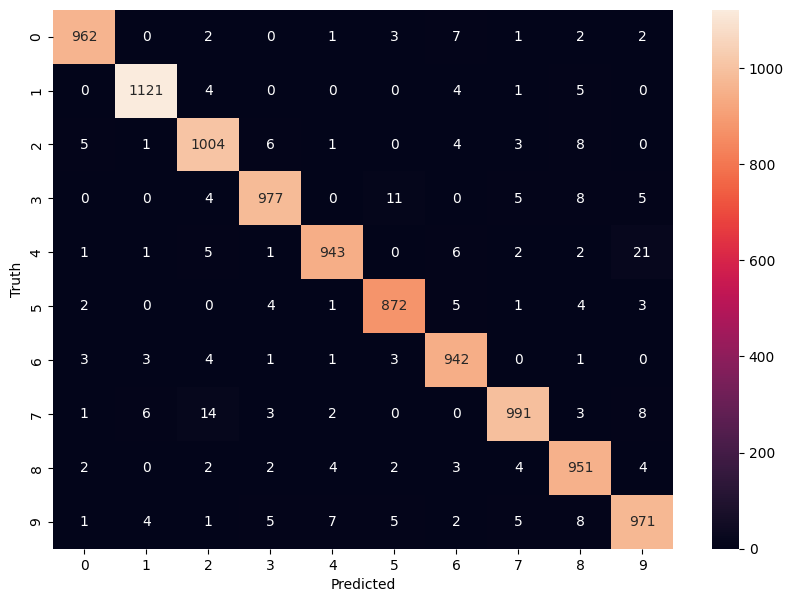

In [ ]:
y_predicted = model.predict(X_test_flattened)
y_predicted_labels = [np.argmax(i) for i in y_predicted]
cm = tf.math.confusion_matrix(labels=y_test,predictions=y_predicted_labels)

plt.figure(figsize = (10,7))
sn.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Truth')

<h3 style='color:purple'>Using Flatten layer so that we don't have to call .reshape on input dataset</h3>

In [ ]:
cnn_model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(100, activation='relu'),
    keras.layers.Dense(10, activation='sigmoid')
])

cnn_model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

cnn_model.fit(X_train, y_train, epochs=10)

d:\Users\leong\Downloads\Lecture Notes\Year 3\Semester 2\ELET3405 - Practical Analysis of Advanced Electronics Circuits ad Systems\.venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9225 - loss: 0.2716
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9641 - loss: 0.1214
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9746 - loss: 0.0856
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9804 - loss: 0.0653
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9843 - loss: 0.0511
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9866 - loss: 0.0420
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9893 - loss: 0.0342
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9903 - loss: 0.0297
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9924 - loss: 0.0238
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9939 - loss: 0.0205


In [ ]:
cnn_model.evaluate(X_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9767 - loss: 0.0850


[0.08497722446918488, 0.9767000079154968]

In [ ]:
# Custom dataset evaluation (./digits) for ANN
# Evaluate
custom_loss, custom_accuracy = model.evaluate(X_custom_flattened, y_custom, verbose=0)
print(f"Custom dataset loss: {custom_loss:.4f}")
print(f"Custom dataset accuracy: {custom_accuracy:.4f}")
 
y_custom_pred = model.predict(X_custom_flattened, verbose=0)
y_custom_pred_labels = [np.argmax(i) for i in y_custom_pred]

Custom dataset loss: 21.5808
Custom dataset accuracy: 0.0333


tf.Tensor(
[[0 0 2 0 0 1 0 0 0 0]
 [0 0 3 0 0 0 0 0 0 0]
 [0 0 1 0 0 2 0 0 0 0]
 [0 0 3 0 0 0 0 0 0 0]
 [0 0 2 0 0 1 0 0 0 0]
 [0 0 3 0 0 0 0 0 0 0]
 [0 0 3 0 0 0 0 0 0 0]
 [0 0 3 0 0 0 0 0 0 0]
 [0 0 3 0 0 0 0 0 0 0]
 [0 0 3 0 0 0 0 0 0 0]], shape=(10, 10), dtype=int32)


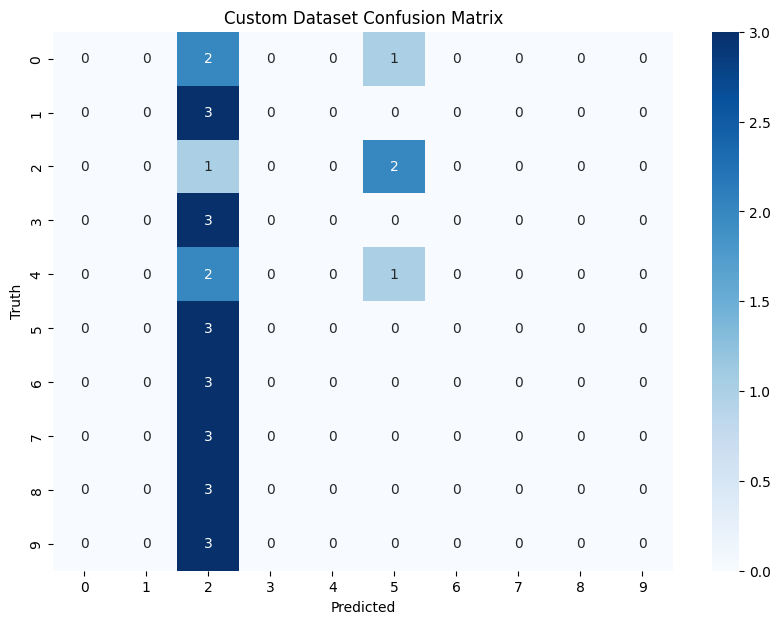


Per-sample predictions:
01. True=0 | Pred=2 | Conf=1.000 | ✗
02. True=0 | Pred=2 | Conf=1.000 | ✗
03. True=0 | Pred=5 | Conf=1.000 | ✗
04. True=1 | Pred=2 | Conf=1.000 | ✗
05. True=1 | Pred=2 | Conf=1.000 | ✗
06. True=1 | Pred=2 | Conf=1.000 | ✗
07. True=2 | Pred=5 | Conf=1.000 | ✗
08. True=2 | Pred=2 | Conf=1.000 | ✓
09. True=2 | Pred=5 | Conf=1.000 | ✗
10. True=3 | Pred=2 | Conf=1.000 | ✗
11. True=3 | Pred=2 | Conf=1.000 | ✗
12. True=3 | Pred=2 | Conf=1.000 | ✗
13. True=4 | Pred=2 | Conf=1.000 | ✗
14. True=4 | Pred=5 | Conf=1.000 | ✗
15. True=4 | Pred=2 | Conf=1.000 | ✗
16. True=5 | Pred=2 | Conf=1.000 | ✗
17. True=5 | Pred=2 | Conf=1.000 | ✗
18. True=5 | Pred=2 | Conf=1.000 | ✗
19. True=6 | Pred=2 | Conf=1.000 | ✗
20. True=6 | Pred=2 | Conf=1.000 | ✗
21. True=6 | Pred=2 | Conf=1.000 | ✗
22. True=7 | Pred=2 | Conf=1.000 | ✗
23. True=7 | Pred=2 | Conf=1.000 | ✗
24. True=7 | Pred=2 | Conf=1.000 | ✗
25. True=8 | Pred=2 | Conf=1.000 | ✗
26. True=8 | Pred=2 | Conf=1.000 | ✗
27. True=8 | 

In [ ]:

# Predict probabilities and labels
y_custom_pred = model.predict(X_custom_flattened, verbose=0)
y_custom_pred_labels = [np.argmax(i) for i in y_custom_pred]

# Confusion matrix
cm_custom = tf.math.confusion_matrix(labels=y_custom, predictions=y_custom_pred_labels, num_classes=10)
print(cm_custom)

# Plot confusion matrix heatmap
plt.figure(figsize=(10, 7))
sn.heatmap(cm_custom, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.title('Custom Dataset Confusion Matrix')
plt.show()

# Per-sample prediction summary
print("\nPer-sample predictions:")
correct = 0
for i, (true_label, pred_label) in enumerate(zip(y_custom, y_custom_pred_labels)):
    conf = float(np.max(y_custom_pred[i]))
    mark = "✓" if pred_label == true_label else "✗"
    if pred_label == true_label:
        correct += 1
    print(f"{i+1:02d}. True={int(true_label)} | Pred={int(pred_label)} | Conf={conf:.3f} | {mark}")

print(f"\nSummary: {correct}/{len(y_custom)} correct ({(100*correct/len(y_custom)):.1f}%)")

Custom dataset loss: 45.0952
Custom dataset accuracy: 0.1000
tf.Tensor(
[[0 0 0 3 0 0 0 0 0 0]
 [0 0 0 3 0 0 0 0 0 0]
 [0 0 0 3 0 0 0 0 0 0]
 [0 0 0 3 0 0 0 0 0 0]
 [0 0 0 3 0 0 0 0 0 0]
 [0 0 0 3 0 0 0 0 0 0]
 [0 0 0 3 0 0 0 0 0 0]
 [0 0 0 3 0 0 0 0 0 0]
 [0 0 0 3 0 0 0 0 0 0]
 [0 0 0 3 0 0 0 0 0 0]], shape=(10, 10), dtype=int32)


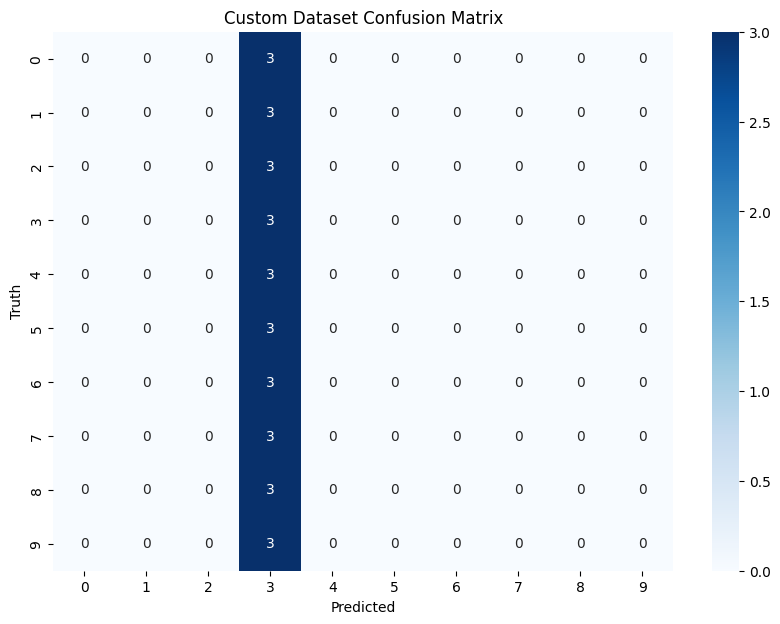


Per-sample predictions:
01. True=0 | Pred=3 | Conf=1.000 | ✗
02. True=0 | Pred=3 | Conf=1.000 | ✗
03. True=0 | Pred=3 | Conf=1.000 | ✗
04. True=1 | Pred=3 | Conf=1.000 | ✗
05. True=1 | Pred=3 | Conf=1.000 | ✗
06. True=1 | Pred=3 | Conf=1.000 | ✗
07. True=2 | Pred=3 | Conf=1.000 | ✗
08. True=2 | Pred=3 | Conf=1.000 | ✗
09. True=2 | Pred=3 | Conf=1.000 | ✗
10. True=3 | Pred=3 | Conf=1.000 | ✓
11. True=3 | Pred=3 | Conf=1.000 | ✓
12. True=3 | Pred=3 | Conf=1.000 | ✓
13. True=4 | Pred=3 | Conf=1.000 | ✗
14. True=4 | Pred=3 | Conf=1.000 | ✗
15. True=4 | Pred=3 | Conf=1.000 | ✗
16. True=5 | Pred=3 | Conf=1.000 | ✗
17. True=5 | Pred=3 | Conf=1.000 | ✗
18. True=5 | Pred=3 | Conf=1.000 | ✗
19. True=6 | Pred=3 | Conf=1.000 | ✗
20. True=6 | Pred=3 | Conf=1.000 | ✗
21. True=6 | Pred=3 | Conf=1.000 | ✗
22. True=7 | Pred=3 | Conf=1.000 | ✗
23. True=7 | Pred=3 | Conf=1.000 | ✗
24. True=7 | Pred=3 | Conf=1.000 | ✗
25. True=8 | Pred=3 | Conf=1.000 | ✗
26. True=8 | Pred=3 | Conf=1.000 | ✗
27. True=8 | 

In [ ]:
# Custom dataset evaluation (./digits) for CNN

# Evaluate
custom_loss, custom_accuracy = cnn_model.evaluate(x_custom, y_custom, verbose=0)
print(f"Custom dataset loss: {custom_loss:.4f}")
print(f"Custom dataset accuracy: {custom_accuracy:.4f}")

# Predict probabilities and labels
y_custom_pred = cnn_model.predict(x_custom, verbose=0)
y_custom_pred_labels = [np.argmax(i) for i in y_custom_pred]

# Confusion matrix
cm_custom = tf.math.confusion_matrix(labels=y_custom, predictions=y_custom_pred_labels, num_classes=10)
print(cm_custom)

# Plot confusion matrix heatmap
plt.figure(figsize=(10, 7))
sn.heatmap(cm_custom, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.title('Custom Dataset Confusion Matrix')
plt.show()

# Per-sample prediction summary
print("\nPer-sample predictions:")
correct = 0
for i, (true_label, pred_label) in enumerate(zip(y_custom, y_custom_pred_labels)):
    conf = float(np.max(y_custom_pred[i]))
    mark = "✓" if pred_label == true_label else "✗"
    if pred_label == true_label:
        correct += 1
    print(f"{i+1:02d}. True={int(true_label)} | Pred={int(pred_label)} | Conf={conf:.3f} | {mark}")

print(f"\nSummary: {correct}/{len(y_custom)} correct ({(100*correct/len(y_custom)):.1f}%)")

### Results

This did not perform as well as the cnn in the digits_recognition_neural_network.ipynb file since it did not have a pooling layer and as defined input but still better than the the nueral network, ann.

```python
    layers.Conv2D(30, (3,3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2,2)),
 
    layers.Flatten(),
    layers.Dense(100, activation='relu'),
    keras.layers.Dense(10, activation='sigmoid')
```